Lead Scoring: Classification Homework

In [6]:
import pandas as pd
import numpy as np

In [1]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [2]:
!wget $data

--2026-10-30 11:44:30--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv.1’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.05s   

2026-10-30 11:44:30 (5.40 MB/s) - ‘course_lead_scoring_2026.csv.1’ saved [278746/278746]



In [3]:
!head course_lead_scoring_2026.csv

lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
organic_search,technology,employed,europe,88160,3,4,0.64,1
social_media,technology,employed,south_america,72688,3,7,0.72,1
referral,retail,employed,europe,44697,3,4,0.58,1
paid_ads,manufacturing,student,,,3,6,0.57,0
referral,manufacturing,student,north_america,24062,4,5,0.62,1
referral,manufacturing,employed,africa,43841,3,5,0.77,1
,education,employed,north_america,58738,3,9,0.78,1
paid_ads,technology,employed,north_america,95059,2,4,0.41,1
organic_search,healthcare,employed,asia,62565,3,6,0.52,1


In [7]:
data = pd.read_csv('course_lead_scoring_2026.csv')

In [8]:
data.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [10]:
data.describe().round(2)

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4631.00,5000.00,5000.00,4965.00,5000.00
mean,54533.21,2.09,4.47,0.49,0.58
std,21245.66,1.19,2.44,0.20,0.49
min,12000.00,0.00,0.00,0.01,0.00
25%,40458.50,1.00,3.00,0.36,0.00
50%,55051.00,2.00,4.00,0.49,1.00
75%,71252.50,3.00,6.00,0.63,1.00
max,109886.00,6.00,13.00,0.99,1.00


In [12]:
missing_values = data.isna().sum()
missing_values = missing_values[missing_values > 0]

print(missing_values)

lead_source          148
industry             240
employment_status    194
location             208
annual_income        369
lead_score            35
dtype: int64


In [14]:
categorical_columns = ['lead_source', 'industry', 'employment_status', 'location']
numerical_columns = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [15]:
data[categorical_columns] = data[categorical_columns].fillna("NA")
data[numerical_columns] = data[numerical_columns].fillna(0.0)

In [16]:
print(data.isna().sum())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


Question 1: Most frequent observation mode for industry

In [17]:
data['industry'].value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

Question 2: Correlation Matrix for the numerical columns

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [21]:
# numerical_columns is a list of column names
correlation_matrix = data[numerical_columns].corr()

print(correlation_matrix)

                          annual_income  number_of_courses_viewed  \
annual_income                  1.000000                  0.161300   
number_of_courses_viewed       0.161300                  1.000000   
interaction_count              0.122842                  0.721609   
lead_score                     0.229496                  0.757204   

                          interaction_count  lead_score  
annual_income                      0.122842    0.229496  
number_of_courses_viewed           0.721609    0.757204  
interaction_count                  1.000000    0.915746  
lead_score                         0.915746    1.000000  


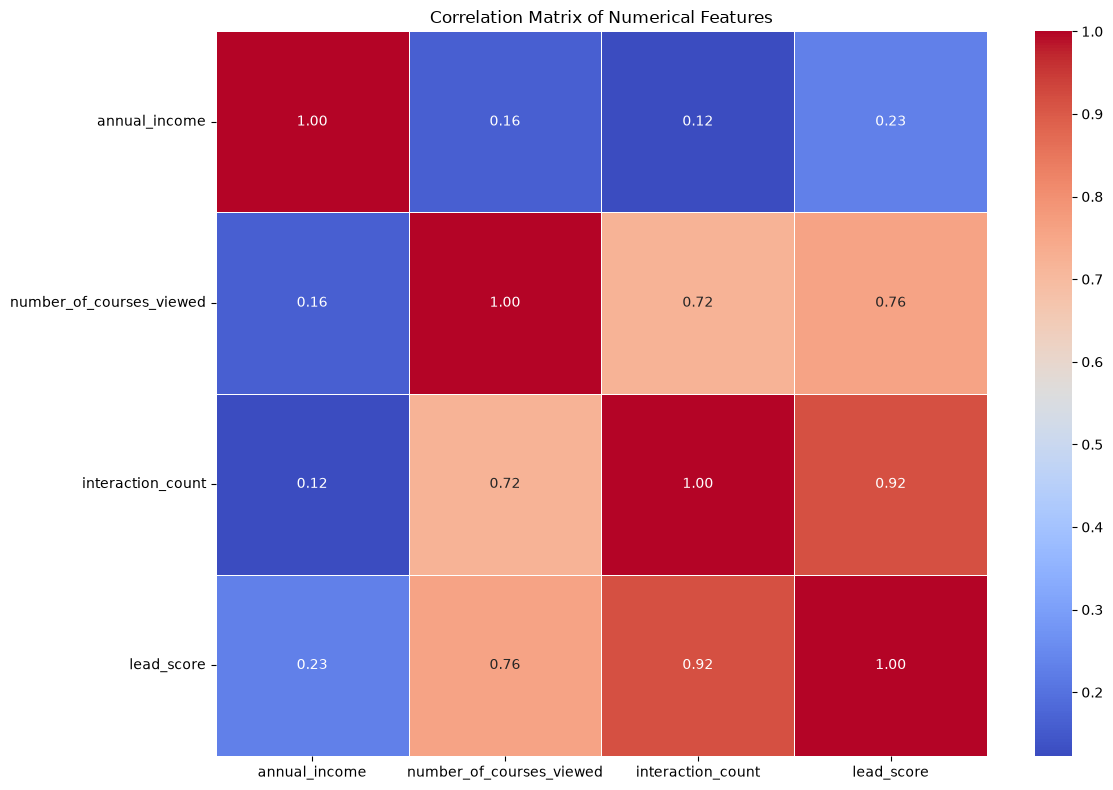

In [22]:
# Plot the matrix
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

Splitting the data

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
df_full_train, df_test = train_test_split(data, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

In [25]:
len(data), len(df_full_train), len(df_train), len(df_val), len(df_test)

(5000, 4000, 3000, 1000, 1000)

In [26]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [27]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [28]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

Question 3: Calculating the mutual information score between converted and other categorical colums using the training set only

In [32]:
from sklearn.metrics import mutual_info_score
from itertools import combinations

In [35]:
# Store scores for each categorical column
mutual_information_scores = {}

for col in categorical_columns:
    score = mutual_info_score(df_train[col], y_train)
    mutual_information_scores[col] = score

# Print scores from highest to lowest
for col, score in sorted(
    mutual_information_scores.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"Mutual Information between 'converted' and '{col}': {score:.4f}")

Mutual Information between 'converted' and 'lead_source': 0.0343
Mutual Information between 'converted' and 'employment_status': 0.0190
Mutual Information between 'converted' and 'industry': 0.0020
Mutual Information between 'converted' and 'location': 0.0010


In [34]:
for col1, col2 in combinations(categorical_columns, 2):
    score = mutual_info_score(df_train[col1], df_train[col2])

    print(
        f"Mutual Information between '{col1}' and '{col2}': "
        f"{score:.4f}"
    )

Mutual Information between 'lead_source' and 'industry': 0.0042
Mutual Information between 'lead_source' and 'employment_status': 0.0040
Mutual Information between 'lead_source' and 'location': 0.0032
Mutual Information between 'industry' and 'employment_status': 0.0038
Mutual Information between 'industry' and 'location': 0.0052
Mutual Information between 'employment_status' and 'location': 0.0035


Question 4: Training a logistic regression and finding the accuracy 

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

In [39]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns,
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns,
        ),
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                solver="liblinear",
                C=1.0,
                max_iter=1000,
                random_state=42,
            ),
        ),
    ]
)

model.fit(df_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['lead_source','industry','employment_status',..., 'number_of_courses_viewed','interaction_count','lead_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``

In [40]:
y_pred = model.predict(df_val)
y_pred_proba = model.predict_proba(df_val)[:, 1]

In [42]:
print("Accuracy:", accuracy_score(y_val, y_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_pred_proba))

Accuracy: 0.645
ROC-AUC: 0.7287097189836693


Question 5: Training the model without every feature and finding the difference in accuracy

In [43]:
df_train.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score'],
      dtype='str')

In [44]:
# Combine the existing categorical and numerical column names
all_features = list(categorical_columns) + list(numerical_columns)

results = []

# Evaluate the baseline model using all features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            list(categorical_columns),
        ),
        (
            "numerical",
            "passthrough",
            list(numerical_columns),
        ),
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                solver="liblinear",
                C=1.0,
                max_iter=1000,
                random_state=42,
            ),
        ),
    ]
)

model.fit(df_train, y_train)
baseline_predictions = model.predict(df_val)
baseline_accuracy = accuracy_score(y_val, baseline_predictions)

results.append(
    {
        "removed_feature": "None",
        "accuracy": baseline_accuracy,
    }
)

# Remove one feature at a time and retrain the model
for feature_to_remove in all_features:
    features_to_use = [
        feature for feature in all_features
        if feature != feature_to_remove
    ]

    categorical_features = [
        feature for feature in categorical_columns
        if feature != feature_to_remove
    ]

    numerical_features = [
        feature for feature in numerical_columns
        if feature != feature_to_remove
    ]

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features,
            ),
            (
                "numerical",
                "passthrough",
                numerical_features,
            ),
        ]
    )

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                LogisticRegression(
                    solver="liblinear",
                    C=1.0,
                    max_iter=1000,
                    random_state=42,
                ),
            ),
        ]
    )

    model.fit(df_train[features_to_use], y_train)

    predictions = model.predict(df_val[features_to_use])
    accuracy = accuracy_score(y_val, predictions)

    results.append(
        {
            "removed_feature": feature_to_remove,
            "accuracy": accuracy,
        }
    )

# Display results, sorted by accuracy
results_df = pd.DataFrame(results).sort_values(
    by="accuracy",
    ascending=False,
)

print(results_df)

            removed_feature  accuracy
5             annual_income     0.724
0                      None     0.645
2                  industry     0.645
4                  location     0.645
3         employment_status     0.645
8                lead_score     0.644
6  number_of_courses_viewed     0.643
1               lead_source     0.642
7         interaction_count     0.601


In [46]:
results_df["accuracy_change"] = (
    results_df["accuracy"] - baseline_accuracy
)

print(results_df)

            removed_feature  accuracy  accuracy_change
5             annual_income     0.724            0.079
0                      None     0.645            0.000
2                  industry     0.645            0.000
4                  location     0.645            0.000
3         employment_status     0.645            0.000
8                lead_score     0.644           -0.001
6  number_of_courses_viewed     0.643           -0.002
1               lead_source     0.642           -0.003
7         interaction_count     0.601           -0.044


Question 6: Training the model using regularization

In [49]:
# Preprocessing for all features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            list(categorical_columns),
        ),
        (
            "numerical",
            "passthrough",
            list(numerical_columns),
        ),
    ]
)

# Values of C to evaluate
c_values = [0.000001, 0.00001, 0.0001, 0.001]

results = []

for c_value in c_values:
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                LogisticRegression(
                    solver="liblinear",
                    C=c_value,
                    max_iter=1000,
                    random_state=42,
                ),
            ),
        ]
    )

    # Train using all features
    model.fit(df_train, y_train)

    # Evaluate on the validation dataset
    y_val_pred = model.predict(df_val)
    accuracy = round(accuracy_score(y_val, y_val_pred), 3)

    results.append(
        {
            "C": c_value,
            "accuracy": accuracy,
        }
    )

# Display the results
results_df = pd.DataFrame(results)

print(results_df)

          C  accuracy
0  0.000001     0.598
1  0.000010     0.598
2  0.000100     0.613
3  0.001000     0.645
